In [1]:
import os
import kagglehub
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

C:\Users\akobr\mu25-ml-group-2\.pixi\envs\default\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("olaflundstrom/nordcauc-urban-mobility-intelligence")
print(os.listdir(path))

['micromobility_trips.csv', 'pedestrian_flow_counters.csv', 'public_transit_ridership.csv', 'traffic_flow_sensors.csv']


In [3]:
df = pd.read_csv(os.path.join(path, 'traffic_flow_sensors.csv'))
df.shape

(200000, 30)

### Målet: trafiken 60 minuter fram

**Problem:** Vi vill förutsäga trafikklassen (free_flow, light, moderate, heavy) 60 minuter framåt, utifrån vad vi vet nu.

**Hur:** För varje mätning hämtar vi trafikklassen från samma sensors nästa mätning (`groupby('sensor_id')` och `shift(-1)`), och behåller bara rader där nästa mätning är exakt 60 minuter senare. Kolumnen heter `future_congestion_level`. Kvar blir 2 270 av 200 000 rader (ca 1 %), eftersom få sensorer har en mätning exakt en timme senare.

In [4]:
df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = pd.to_datetime(df['next_timestamp']) - pd.to_datetime(df['timestamp'])

df = df[df['duration_to_next'].dt.total_seconds() / 60 == 60]

In [5]:
len(df)

2270

In [6]:
df.head()

,sensor_id,city,country,district,timestamp,date,hour,day_of_week,is_weekend,is_public_holiday,...,precipitation_mm,weather_condition,incident_type,ai_predicted_volume,ai_predicted_congestion,ai_model_version,data_quality_flag,future_congestion_level,next_timestamp,duration_to_next
162,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-05-28 20:45:00,2023-05-28,20,Sunday,True,False,...,0.5,light_rain,none,124,moderate,NordFlow-GNN,good,moderate,2023-05-28 21:45:00,0 days 01:00:00
311,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-09-21 13:45:00,2023-09-21,13,Thursday,False,False,...,2.2,light_rain,none,18,free_flow,NordFlow-GNN,good,free_flow,2023-09-21 14:45:00,0 days 01:00:00
419,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-01-10 17:30:00,2024-01-10,17,Wednesday,False,False,...,0.0,sleet,none,211,heavy,NordFlow-GNN,good,heavy,2024-01-10 18:30:00,0 days 01:00:00
505,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-03-22 00:15:00,2024-03-22,0,Friday,False,False,...,0.0,partly_cloudy,none,19,free_flow,NordFlow-GNN,good,free_flow,2024-03-22 01:15:00,0 days 01:00:00
558,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-04-29 14:30:00,2024-04-29,14,Monday,False,False,...,2.4,drizzle,none,23,free_flow,NordFlow-GNN,good,free_flow,2024-04-29 15:30:00,0 days 01:00:00


In [7]:
df['future_congestion_level'].value_counts(normalize=True)

future_congestion_level
free_flow    0.473128
moderate     0.182819
light        0.178414
heavy        0.165639
Name: proportion, dtype: float64

### Val av kolumner

Datasetet har 30 kolumner. Vi behåller 17 som beskriver trafiksituationen nu (tid på dygnet, vägtyp, trafikmått, väder, incidenter), samt målet `future_congestion_level`.

**Vi tar bort:** identifierare och plats (sensor_id, city, country, district, latitude, longitude), exakt tidpunkt (timestamp, date), färdiga AI-prognoser (ai_predicted_volume, ai_predicted_congestion, ai_model_version) och data_quality_flag. Gruppen valde också att inte ta med ev_count_15min (antal elbilar)

**Varför:** en modell som ska gälla för alla sensorer ska inte lära sig utantill vilken sensor eller stad en rad kommer från, och de färdiga prognoserna är någon annans gissning som skulle dölja vad vår egen modell lär sig.

Nuvarande trafikklass (`congestion_level`) och hastighet behålls, eftersom vi känner till dem när vi gissar 60 minuter fram.

In [8]:
kolumner = [
    'hour', 'day_of_week', 'is_weekend', 'is_public_holiday', 'season',
    'road_type', 'speed_limit_kmh', 'lane_count', 'vehicle_count_15min',
    'avg_speed_kmh', 'congestion_level', 'occupancy_rate', 'truck_count_15min',
    'temperature_c', 'precipitation_mm', 'weather_condition', 'incident_type', 'future_congestion_level'
]



In [9]:
df = df[kolumner].dropna()

In [10]:
df.isna().sum().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 2270 entries, 162 to 199953
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hour                     2270 non-null   int64  
 1   day_of_week              2270 non-null   str    
 2   is_weekend               2270 non-null   bool   
 3   is_public_holiday        2270 non-null   bool   
 4   season                   2270 non-null   str    
 5   road_type                2270 non-null   str    
 6   speed_limit_kmh          2270 non-null   int64  
 7   lane_count               2270 non-null   int64  
 8   vehicle_count_15min      2270 non-null   int64  
 9   avg_speed_kmh            2270 non-null   float64
 10  congestion_level         2270 non-null   str    
 11  occupancy_rate           2270 non-null   float64
 12  truck_count_15min        2270 non-null   int64  
 13  temperature_c            2270 non-null   float64
 14  precipitation_mm         2270 non-nu

In [12]:
df.describe()

,hour,speed_limit_kmh,lane_count,vehicle_count_15min,avg_speed_kmh,occupancy_rate,truck_count_15min,temperature_c,precipitation_mm
count,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000
mean,11.337445,64.581498,2.631718,266.488106,53.467225,0.251278,9.396035,16.279956,0.512159
std,6.865628,22.445786,0.982912,324.686855,22.881421,0.196372,11.356147,12.456725,1.174506
min,0.000000,30.000000,1.000000,9.000000,6.300000,0.031000,0.000000,-6.800000,0.000000
25%,6.000000,50.000000,2.000000,60.000000,37.100000,0.071000,2.000000,6.100000,0.000000
50%,11.000000,60.000000,2.000000,159.000000,49.750000,0.237000,6.000000,16.150000,0.000000
75%,17.000000,80.000000,3.000000,317.000000,67.400000,0.379750,12.000000,28.300000,0.500000
max,23.000000,130.000000,5.000000,2685.000000,131.300000,0.703000,83.000000,39.100000,11.600000


In [13]:
len(df)

2270

### Antal fordon per 15 minuter

**Fråga:** Hur är antalet fordon (vehicle_count_15min) fördelat?

**Varför:** Vi vill lära känna datan och kontrollera att den ser rimlig ut innan vi tränar en modell.

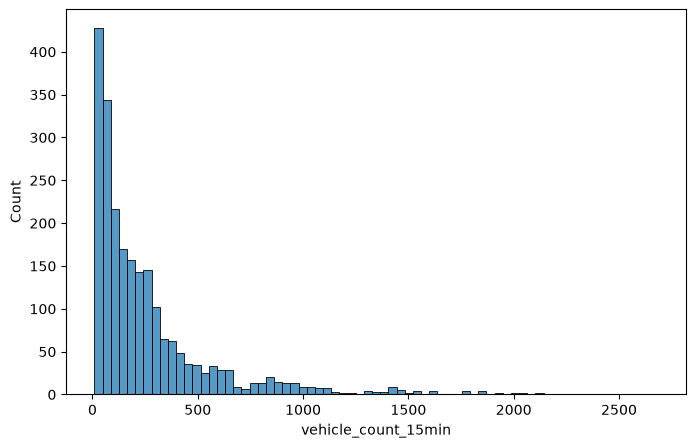

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='vehicle_count_15min')
plt.show()

**Resultat:** De flesta mätningar har få fordon, och några få har mycket högre värden. Fördelningen är alltså skev åt höger. Därför är medianen en bättre bild av ett typiskt värde än medelvärdet, som dras upp av de extrema värdena.

### Fördelning av målvariabeln

**Fråga**: Är de fyra trafikklasserna (free_flow, light, moderate, heavy) jämnt fördelade, eller är någon klass mycket vanligare?

**Varför:** Om en klass dominerar kan en modell få hög accuracy genom att alltid gissa den klassen. Då behöver vi veta vad en enkel gissning ger för att kunna bedöma om modellen faktiskt lär sig något.

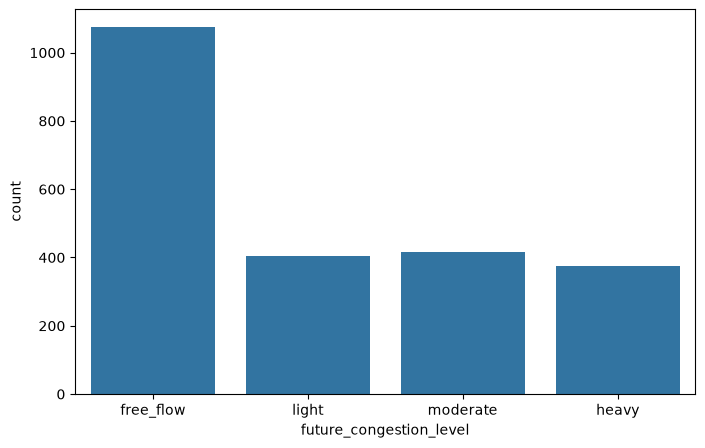

In [15]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='future_congestion_level', order=['free_flow', 'light', 'moderate', 'heavy'])
plt.show()

In [16]:
df['future_congestion_level'].value_counts(normalize=True)

future_congestion_level
free_flow    0.473128
moderate     0.182819
light        0.178414
heavy        0.165639
Name: proportion, dtype: float64

### Resultat

free_flow är vanligast (47,3 %) och heavy minst (16,6 %).

Att alltid gissa free_flow ger alltså 47,3 % rätt, och det är vår baslinje.

En modell måste slå 47,3 % på testdatan för att visa att den har lärt sig något.

### Trafikbelastning per timme

**Fråga:** Varierar trafikklassen 60 minuter fram (future_congestion_level) beroende på tid på dygnet?

**Varför:** Timmen är känd i förväg, så den kan användas för att förutsäga framtida trafik. Om heavy är vanligare vid vissa timmar (t.ex. rusningstid) separerar hour klasserna och är en användbar feature.

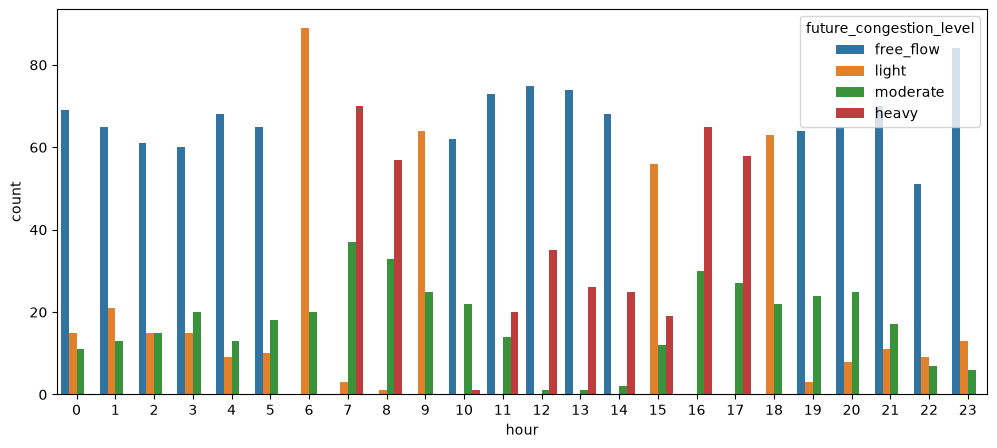

In [17]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='hour', hue='future_congestion_level', hue_order=['free_flow', 'light', 'moderate', 'heavy'])
plt.show()

**Resultat:** Heavy är vanligast kl. 7-8 och 16-17, en timme före själva rusningstiden, eftersom `hour` är klockslaget för mätningen men trafikklassen gäller 60 minuter senare. 

Light är vanligast strax före och efter topparna (kl. 6, 9, 15 och 18). Free_flow är vanligast nattetid (0-5), mitt på dagen (10-14) och sent på kvällen (19-23). 

Klasserna fördelas alltså tydligt olika över dygnet, så `hour` separerar klasserna väl. Det gör `hour` till en användbar feature, och eftersom timmen är känd i förväg kan den användas för att förutsäga framtida trafik.

### Trafikbelastning per väder

**Fråga:** Påverkar vädret (weather_condition) vilken trafikklass vi får?

**Varför:** Väder är något vi kan känna till i förväg (t.ex. via väderprognos), så det kan användas för att förutsäga framtida trafik. Om fördelningen av trafikklasser skiljer sig mellan väderförhållanden separerar vädret klasserna och är en användbar feature.

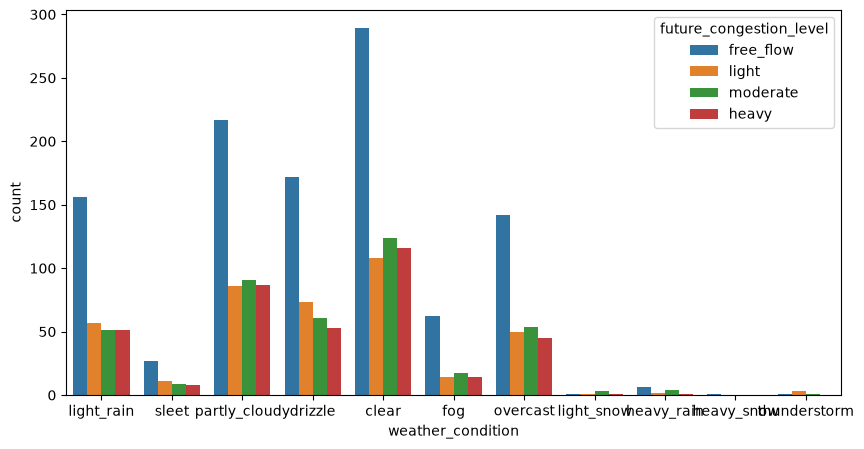

In [18]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='weather_condition', hue='future_congestion_level', hue_order=['free_flow', 'light', 'moderate', 'heavy'])
plt.show()

In [19]:
df.groupby('weather_condition')['future_congestion_level'].value_counts(normalize=True)

weather_condition  future_congestion_level
clear              free_flow                  0.453689
                   moderate                   0.194662
                   heavy                      0.182104
                   light                      0.169545
drizzle            free_flow                  0.479109
                   light                      0.203343
                   moderate                   0.169916
                   heavy                      0.147632
fog                free_flow                  0.579439
                   moderate                   0.158879
                   light                      0.130841
                   heavy                      0.130841
heavy_rain         free_flow                  0.461538
                   moderate                   0.307692
                   light                      0.153846
                   heavy                      0.076923
heavy_snow         free_flow                  1.000000
light_rain         fre

In [20]:
df['weather_condition'].value_counts()

weather_condition
clear            637
partly_cloudy    481
drizzle          359
light_rain       315
overcast         291
fog              107
sleet             55
heavy_rain        13
light_snow         6
thunderstorm       5
heavy_snow         1
Name: count, dtype: int64

**Resultat:** De flesta väder har ungefär samma fördelning som totalen (ca 47 % free_flow). Fog har lite fler free_flow (58 %). 

Väder med få rader (heavy_snow, thunderstorm, light_snow) ger extrema procenttal som inte går att lita på. Vädret separerar klasserna svagare än `hour` och är en möjlig men inte avgörande feature. Vi behåller den och testar i modellen om den hjälper.

### Samband mellan siffer-kolumner

**Fråga:** Hur hänger siffer-kolumnerna ihop med varandra?

**Varför:** Kolumner som säger nästan samma sak behövs inte båda två. Vi vill också hitta kolumner som avslöjar svaret, så att vi inte använder dem.

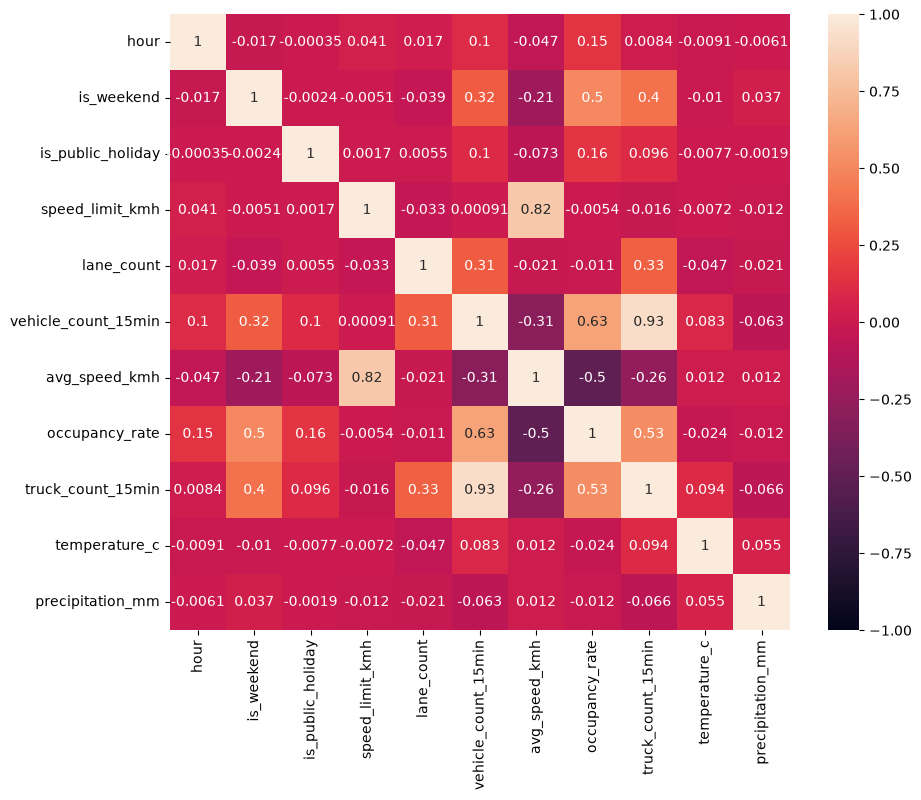

In [21]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, vmin=-1, vmax=1)
plt.show()

**Resultat:** Två par hänger starkt ihop: truck_count_15min och vehicle_count_15min (0,93) samt speed_limit_kmh och avg_speed_kmh (0,82).

Det är logiskt: fler fordon ger fler lastbilar, och vägar med högre hastighetsgräns har högre medelhastighet. Kolumnerna i varje par säger nästan samma sak. Temperatur och nederbörd hänger inte ihop med något (nära 0). Målet är text och syns inte i heatmapen, så det undersöker vi i nästa steg.

### Medelhastighet per trafikklass

**Fråga:** Skiljer sig avg_speed_kmh mellan trafikklasserna 60 minuter fram?

**Varför:** Heatmapen visar bara hur siffer-kolumner hänger ihop med varandra. Målet är text och syns inte där. Därför jämför vi medelvärdet per klass: om det skiljer sig mellan klasserna kan kolumnen hjälpa modellen.

In [22]:
df.groupby('future_congestion_level')['avg_speed_kmh'].mean()

future_congestion_level
free_flow    61.552980
heavy        41.743617
light        49.280247
moderate     47.249639
Name: avg_speed_kmh, dtype: float64

**Resultat:** free_flow (62 km/h) och heavy (42 km/h) skiljer sig tydligt i medelhastighet, light (49) och moderate (47) knappt. Hastigheten är en användbar feature, främst för att skilja free_flow från heavy.

# Det vi har visat

**Målet:** trafikklassen 60 minuter fram (`future_congestion_level`). Free_flow är vanligast (47,3 %), så baslinjen att slå är 47,3 %.

**Timme:** heavy toppar kl. 7-8 och 16-17, så `hour` separerar klasserna tydligt.

**Väder:** de flesta väder liknar totalen, så vädret är en svagare feature.

**Samband:** truck_count och vehicle_count (0,93) samt speed_limit och avg_speed (0,82) säger nästan samma sak.

**Hastighet:** free_flow (62 km/h) och heavy (42 km/h) skiljer sig tydligt, så hastigheten är en användbar feature.